<a href="https://colab.research.google.com/github/SimonYassa/Insider-Threat-and-User-Behavior-Analytics/blob/main/01_eda_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import random
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_DIR = "/content/drive/MyDrive/cert_r42"

Mounted at /content/drive


In [2]:
!ls /content/drive/MyDrive/cert_r42
!ls /content/drive/MyDrive/cert_r42/r4.2

answers  r4.2
device.csv  file.csv  license.txt  psychometric.csv
email.csv   LDAP      logon.csv    readme.txt


In [3]:
import glob, collections
ins = pd.read_csv(f"{DATA_DIR}/answers/insiders.csv", dtype=str)
r42 = ins[ins["dataset"] == "4.2"].copy()
r42["start"] = pd.to_datetime(r42["start"], format="%m/%d/%Y %H:%M:%S")
r42["end"] = pd.to_datetime(r42["end"], format="%m/%d/%Y %H:%M:%S")
print("incidents:", len(r42), "| unique users:", r42["user"].nunique())
print(r42["scenario"].value_counts().to_dict())
print("window length in days:\n", ((r42["end"] - r42["start"]).dt.total_seconds() / 86400).describe().round(1))
print("first start:", r42["start"].min(), "| last end:", r42["end"].max())

files = glob.glob(f"{DATA_DIR}/answers/r4.2-*/*.csv")
types, widths = collections.Counter(), collections.defaultdict(set)
for p in files:
    for line in open(p):
        parts = line.rstrip("\n").split(",")
        types[parts[0]] += 1
        widths[parts[0]].add(len(parts))
print(len(files), "incident files |", dict(types))
print({k: sorted(v) for k, v in widths.items()})

incidents: 70 | unique users: 70
{'1': 30, '2': 30, '3': 10}
window length in days:
 count    70.0
mean     26.1
std      25.6
min       0.0
25%       2.3
50%       7.3
75%      55.4
max      58.5
dtype: float64
first start: 2010-06-10 07:54:10 | last end: 2011-04-29 20:04:27
70 incident files | {'email': 470, 'http': 3860, 'device': 2785, 'file': 10, 'logon': 198}
{'email': [12], 'http': [7], 'device': [6], 'file': [7], 'logon': [6]}


In [4]:
rows = []
for p in glob.glob(f"{DATA_DIR}/answers/r4.2-*/*.csv"):
    for line in open(p):
        parts = line.rstrip("\n").split(",")
        rows.append((parts[0], parts[1], parts[2], parts[3]))   # type, event id, date, user
mal = pd.DataFrame(rows, columns=["type", "event_id", "date", "user"])
mal["date"] = pd.to_datetime(mal["date"], format="%m/%d/%Y %H:%M:%S")
mal["day"] = mal["date"].dt.normalize()

ud = mal.drop_duplicates(["user", "day"]).copy()
ud["month"] = ud["day"].dt.to_period("M")
by_month = pd.DataFrame({
    "events": mal.groupby(mal["date"].dt.to_period("M")).size(),
    "pos_user_days": ud.groupby("month").size(),
    "insiders": ud.groupby("month")["user"].nunique(),
}).fillna(0).astype(int)
by_month["cum_pos_user_days"] = by_month["pos_user_days"].cumsum()
print(by_month)

nonhttp = mal[mal["type"] != "http"]
print("unique event ids == events:", mal["event_id"].nunique() == len(mal))
print("positive user-days, all logs:", len(ud))
print("positive user-days without http:", nonhttp.drop_duplicates(["user", "day"]).shape[0])
print("insiders with >=1 non-http malicious event:", nonhttp["user"].nunique(), "of", mal["user"].nunique())

         events  pos_user_days  insiders  cum_pos_user_days
2010-06     254             43         7                 43
2010-07    1051            159        19                202
2010-08    1191            150        18                352
2010-09     932            119        18                471
2010-10     772            108        18                579
2010-11     720             97        12                676
2010-12     548             64        11                740
2011-01     487             76         8                816
2011-02     712             95        13                911
2011-03     522             61         7                972
2011-04     134             14         6                986
unique event ids == events: True
positive user-days, all logs: 986
positive user-days without http: 541
insiders with >=1 non-http malicious event: 72 of 72


In [5]:
# 1) the extra users
insiders = set(r42["user"])
extra = mal[~mal["user"].isin(insiders)]
print("users in malicious events but not in insiders.csv:", extra["user"].nunique())
print("their events by type:", extra["type"].value_counts().to_dict())
print("insiders with no event under their own name:", len(insiders - set(mal["user"])))

# 2) positive user-days by month (non-web events only)
nh = mal[mal["type"] != "http"].drop_duplicates(["user", "day"]).copy()
nh["month"] = nh["day"].dt.to_period("M")
print(nh.groupby("month").size().to_string())

# 3) candidate cut dates
for cut in ["2010-11-30", "2010-12-31", "2011-01-31"]:
    cut = pd.Timestamp(cut)
    tr, te = nh[nh["day"] <= cut], nh[nh["day"] > cut]
    both = set(tr["user"]) & set(te["user"])
    only_te = set(te["user"]) - set(tr["user"])
    print(cut.date(), "| train pos days:", len(tr), "| test pos days:", len(te),
          "| users in train:", tr["user"].nunique(), "| in test:", te["user"].nunique(),
          "| in both:", len(both), "| only in test:", len(only_te))

users in malicious events but not in insiders.csv: 2
their events by type: {'email': 30, 'logon': 20}
insiders with no event under their own name: 0
month
2010-06    15
2010-07    78
2010-08    83
2010-09    76
2010-10    63
2010-11    50
2010-12    44
2011-01    32
2011-02    50
2011-03    36
2011-04    14
Freq: M
2010-11-30 | train pos days: 365 | test pos days: 176 | users in train: 54 | in test: 26 | in both: 8 | only in test: 18
2010-12-31 | train pos days: 409 | test pos days: 132 | users in train: 58 | in test: 19 | in both: 5 | only in test: 14
2011-01-31 | train pos days: 441 | test pos days: 100 | users in train: 62 | in test: 15 | in both: 5 | only in test: 10


In [6]:
insiders = set(r42["user"])
victims = set(mal["user"]) - insiders

pos = (mal[(mal["type"] != "http") & mal["user"].isin(insiders)]
       .drop_duplicates(["user", "day"])[["user", "day"]]
       .assign(action="positive", reason="malicious non-web event"))

web = (mal[(mal["type"] == "http") & mal["user"].isin(insiders)]
       .drop_duplicates(["user", "day"])[["user", "day"]]
       .merge(pos[["user", "day"]], how="left", on=["user", "day"], indicator=True))
web = (web[web["_merge"] == "left_only"][["user", "day"]]
       .assign(action="exclude", reason="web-only malicious day"))

vic = (mal[mal["user"].isin(victims)].drop_duplicates(["user", "day"])[["user", "day"]]
       .assign(action="exclude", reason="victim account used by an insider"))

rules = pd.concat([pos, web, vic], ignore_index=True)
print(rules.groupby(["action", "reason"]).size().to_string())

CUT = pd.Timestamp("2010-12-31")
p_tr, p_te = pos[pos["day"] <= CUT], pos[pos["day"] > CUT]
print("train positives:", len(p_tr), "| insiders:", p_tr["user"].nunique())
print("test positives:", len(p_te), "| insiders:", p_te["user"].nunique())
print("insiders with positives on both sides:", len(set(p_tr["user"]) & set(p_te["user"])))

rules.to_csv(f"{DATA_DIR}/label_rules.csv", index=False)

action    reason                           
exclude   victim account used by an insider     20
          web-only malicious day               445
positive  malicious non-web event              521
train positives: 391 | insiders: 56
test positives: 130 | insiders: 18
insiders with positives on both sides: 4


In [7]:
!cat {DATA_DIR}/answers/scenarios.txt

Brief Scenario Descriptions

1. User who did not previously use removable drives or work after
hours begins logging in after hours, using a removable drive, and
uploading data to wikileaks.org. Leaves the organization shortly
thereafter.

2. User begins surfing job websites and soliciting employment from a
competitor. Before leaving the company, they use a thumb drive (at
markedly higher rates than their previous activity) to steal data.

3. System administrator becomes disgruntled. Downloads a keylogger and
uses a thumb drive to transfer it to his supervisor's machine. The
next day, he uses the collected keylogs to log in as his supervisor
and send out an alarming mass email, causing panic in the
organization. He leaves the organization immediately.

4. A user logs into another user's machine and searches for
interesting files, emailing to their home email. This behavior occurs
more and more frequently over a 3 month period.

5. A member of a group decimated by layoffs uploads documen

--- logon ---
rows: 854859 | users: 1000 | pcs: 1003
date range: 2010-01-02 06:49:00 to 2011-05-17 06:43:35
unparsed dates: 0 | duplicate ids: 0 | exact duplicate rows: 0
missing values: {}
activity: {'Logon': 470591, 'Logoff': 384268}
--- device ---
rows: 405380 | users: 265 | pcs: 971
date range: 2010-01-02 07:21:06 to 2011-05-16 23:22:34
unparsed dates: 0 | duplicate ids: 0 | exact duplicate rows: 0
missing values: {}
activity: {'Connect': 203339, 'Disconnect': 202041}
--- file ---
rows: 445581 | users: 264 | pcs: 956
date range: 2010-01-02 07:23:14 to 2011-05-16 23:22:34
unparsed dates: 0 | duplicate ids: 0 | exact duplicate rows: 0
missing values: {}


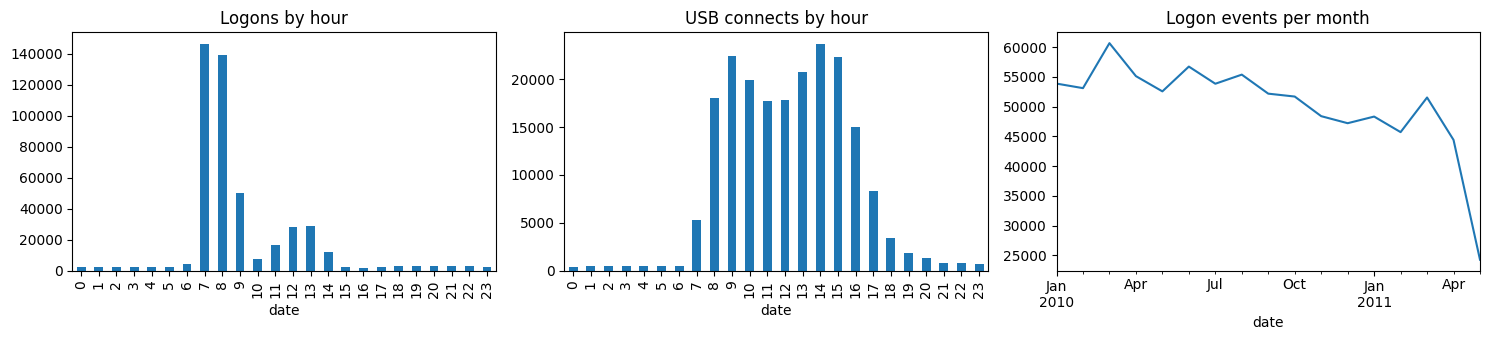

In [8]:
import matplotlib.pyplot as plt
R = f"{DATA_DIR}/r4.2"
FMT = "%m/%d/%Y %H:%M:%S"

logs = {
    "logon":  pd.read_csv(f"{R}/logon.csv",  usecols=["id", "date", "user", "pc", "activity"]),
    "device": pd.read_csv(f"{R}/device.csv", usecols=["id", "date", "user", "pc", "activity"]),
    "file":   pd.read_csv(f"{R}/file.csv",   usecols=["id", "date", "user", "pc"]),
}
for name, df in logs.items():
    df["date"] = pd.to_datetime(df["date"], format=FMT, errors="coerce")
    print(f"--- {name} ---")
    print("rows:", len(df), "| users:", df["user"].nunique(), "| pcs:", df["pc"].nunique())
    print("date range:", df["date"].min(), "to", df["date"].max())
    print("unparsed dates:", df["date"].isna().sum(), "| duplicate ids:", df["id"].duplicated().sum(),
          "| exact duplicate rows:", df.duplicated().sum())
    print("missing values:", df.isna().sum()[lambda s: s > 0].to_dict())
    if "activity" in df:
        print("activity:", df["activity"].value_counts().to_dict())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
logs["logon"].query("activity == 'Logon'")["date"].dt.hour.value_counts().sort_index().plot.bar(ax=ax[0], title="Logons by hour")
logs["device"].query("activity == 'Connect'")["date"].dt.hour.value_counts().sort_index().plot.bar(ax=ax[1], title="USB connects by hour")
logs["logon"].groupby(logs["logon"]["date"].dt.to_period("M")).size().plot(ax=ax[2], title="Logon events per month")
plt.tight_layout(); plt.show()